# 05 — Métricas no teste oficial

Avaliação final da CNN residual da rodada de 60 épocas. O checkpoint foi congelado antes de abrir o teste. A época selecionada foi a 34, pela menor perda de validação.

Este notebook lê os artefatos de uma única inferência nas 10.000 imagens oficiais. A execução do notebook usa as probabilidades já gravadas para desenhar as curvas.

In [1]:
import json
from pathlib import Path

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from sklearn.metrics import precision_recall_curve, roc_curve

root = Path.cwd().resolve()
if root.name == 'notebooks':
    root = root.parent
reports = root / 'reports' / 'final_test'
result = json.loads((reports / 'test_metrics.json').read_text(encoding='utf-8'))
metrics = result['metrics']
model = result['model']
display(pd.Series({
    'Rodada': model['run_name'],
    'Épocas da rodada': model['training_epochs'],
    'Época do checkpoint': model['best_epoch'],
    'Critério de seleção': model['selection_metric'],
    'Imagens de teste': metrics['samples'],
    'Acertos': metrics['correct'],
    'Erros': metrics['errors'],
    'SHA-256 do checkpoint': model['checkpoint_sha256'],
}, name='Registro').to_frame())

,Registro
Rodada,residual_60_cpu
Épocas da rodada,60
Época do checkpoint,34
Critério de seleção,val_loss
Imagens de teste,10000
Acertos,8527
Erros,1473
SHA-256 do checkpoint,e6813ac7e8212c27151fc604d566e04fb8e7614915411c...


## Métricas agregadas

A taxa de erro é o complemento da acurácia top-1. A log loss mede a entropia cruzada das probabilidades. ROC AUC e Average Precision são calculadas com cada classe comparada às demais (OvR).

In [2]:
rates = {
    'accuracy': 'Acurácia top-1',
    'error_rate': 'Taxa de erro',
    'balanced_accuracy': 'Acurácia balanceada',
    'top_3_accuracy': 'Acurácia top-3',
    'top_5_accuracy': 'Acurácia top-5',
}
display(pd.Series({name: metrics[key] * 100 for key, name in rates.items()},
                  name='Teste (%)').round(2).to_frame())
averages = ('micro', 'macro', 'weighted')
classification = pd.DataFrame({
    name: [metrics[f'{key}_{avg}'] * 100 for avg in averages]
    for key, name in [
        ('precision', 'Precision (%)'), ('recall', 'Recall (%)'), ('f1', 'F1 (%)'),
        ('roc_auc_ovr', 'ROC AUC OvR (%)'),
        ('average_precision_ovr', 'Average Precision OvR (%)'),
    ]
}, index=['Micro', 'Macro', 'Ponderada'])
display(classification.round(2))
display(pd.Series({
    'Log loss': metrics['log_loss'],
    'Coeficiente de Matthews (MCC)': metrics['mcc'],
    'Kappa de Cohen': metrics['cohen_kappa'],
}, name='Valor no teste').round(4).to_frame())

,Teste (%)
Acurácia top-1,85.27
Taxa de erro,14.73
Acurácia balanceada,85.27
Acurácia top-3,97.02
Acurácia top-5,99.35


,Precision (%),Recall (%),F1 (%),ROC AUC OvR (%),Average Precision OvR (%)
Micro,85.27,85.27,85.27,98.88,93.33
Macro,85.30,85.27,85.21,98.73,92.65
Ponderada,85.30,85.27,85.21,98.73,92.65


,Valor no teste
Log loss,0.5063
Coeficiente de Matthews (MCC),0.8365
Kappa de Cohen,0.8363


## Referência da validação para o mesmo checkpoint

In [3]:
compare = {'accuracy': 'Acurácia', 'precision_macro': 'Precision macro',
           'recall_macro': 'Recall macro', 'f1_macro': 'F1 macro'}
comparison = pd.DataFrame({
    'Validação (%)': {name: model['validation_metrics'][key] * 100 for key, name in compare.items()},
    'Teste (%)': {name: metrics[key] * 100 for key, name in compare.items()},
})
comparison['Teste − validação (p.p.)'] = comparison['Teste (%)'] - comparison['Validação (%)']
display(comparison.round(2))

,Validação (%),Teste (%),Teste − validação (p.p.)
Acurácia,85.52,85.27,-0.25
Precision macro,85.55,85.30,-0.25
Recall macro,85.52,85.27,-0.25
F1 macro,85.47,85.21,-0.26


## Métricas por classe

,precision (%),recall (%),f1-score (%),specificity (%),roc_auc_ovr (%),average_precision_ovr (%),support,true_positive,false_positive,false_negative,true_negative
class,,,,,,,,,,,
cat,71.39,71.1,71.24,96.83,96.40,80.28,1000,711,285,289,8715
dog,80.44,76.1,78.21,97.94,97.93,87.46,1000,761,185,239,8815
bird,82.63,79.9,81.24,98.13,97.78,89.07,1000,799,168,201,8832
deer,87.34,80.0,83.51,98.71,98.58,91.51,1000,800,116,200,8884
airplane,84.53,89.6,86.99,98.18,99.15,94.19,1000,896,164,104,8836
frog,83.59,93.2,88.13,97.97,99.37,95.91,1000,932,183,68,8817
horse,87.71,89.2,88.45,98.61,99.22,95.47,1000,892,125,108,8875
truck,90.20,90.2,90.20,98.91,99.41,96.61,1000,902,98,98,8902
ship,94.63,88.1,91.25,99.44,99.68,97.69,1000,881,50,119,8950


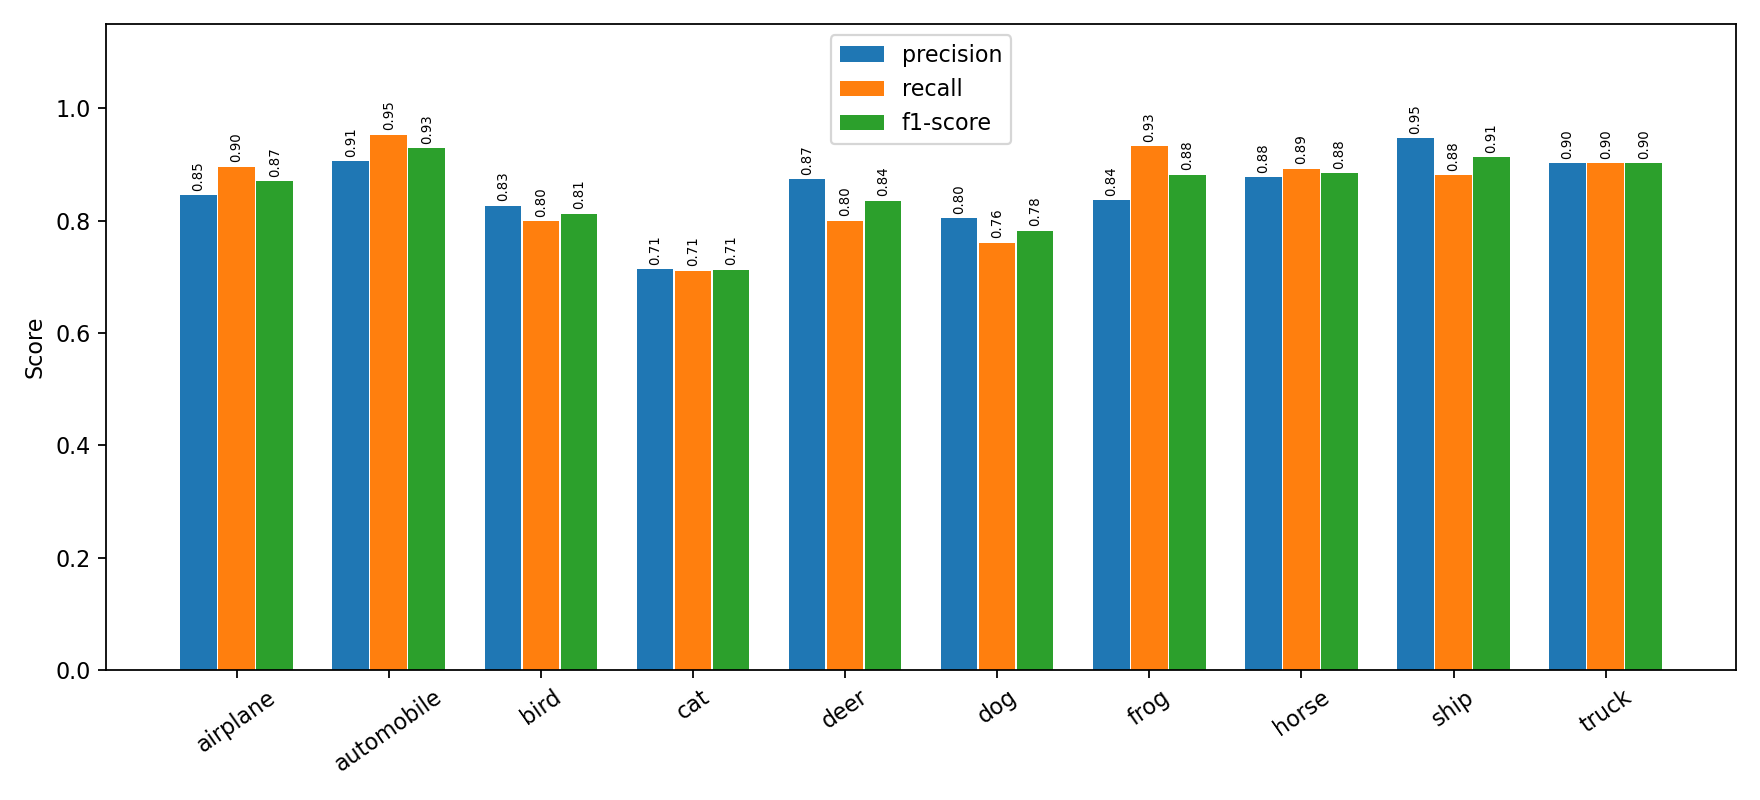

In [4]:
class_report = pd.read_csv(reports / 'test_classification_report.csv', index_col='class')
class_rates = ['precision', 'recall', 'f1-score', 'specificity', 'roc_auc_ovr', 'average_precision_ovr']
by_class = class_report[class_rates].mul(100).round(2).add_suffix(' (%)')
counts = ['support', 'true_positive', 'false_positive', 'false_negative', 'true_negative']
display(by_class.join(class_report[counts].astype(int)).sort_values('f1-score (%)'))
display(Image(filename=str(reports / 'figures/per_class_metrics.png')))

## Matriz de confusão

As linhas são as classes reais e as colunas são as classes previstas. Como cada classe tem 1.000 imagens no teste, as contagens dos pares podem ser comparadas diretamente.

,actual,predicted,Imagens
0,dog,cat,131
1,cat,dog,98
2,cat,frog,60
3,ship,airplane,54
4,deer,bird,48
5,deer,frog,45
6,bird,frog,44
7,deer,cat,41
8,truck,automobile,41
9,bird,cat,37


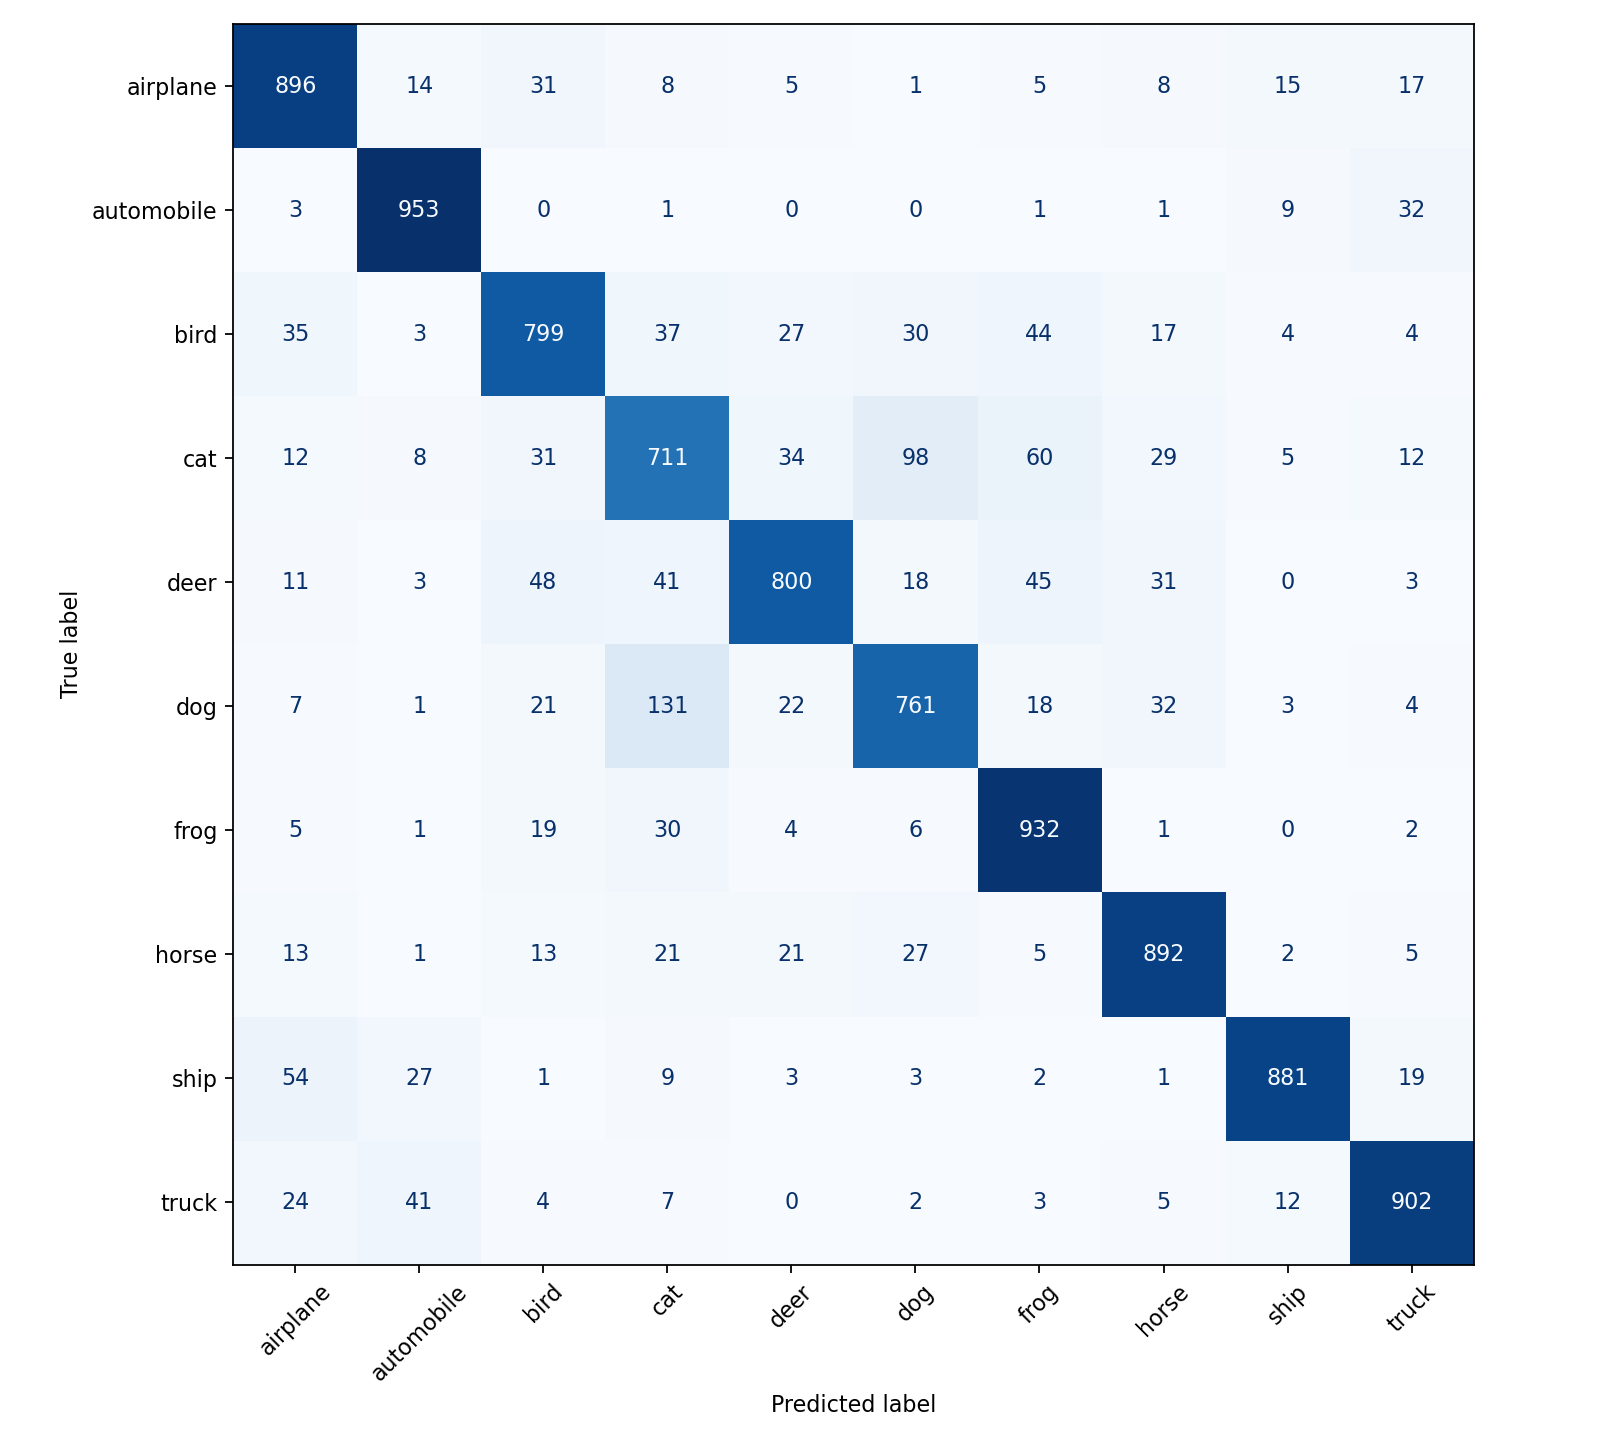

In [5]:
cm = pd.read_csv(reports / 'test_confusion_matrix.csv', index_col='actual')
confusions = cm.rename_axis(columns='predicted').stack().rename('Imagens').reset_index()
off_diagonal = confusions['actual'] != confusions['predicted']
display(confusions.loc[off_diagonal].nlargest(10, 'Imagens').reset_index(drop=True))
display(Image(filename=str(reports / 'figures/confusion_matrix.png')))

## Curvas ROC e Precision–Recall por classe

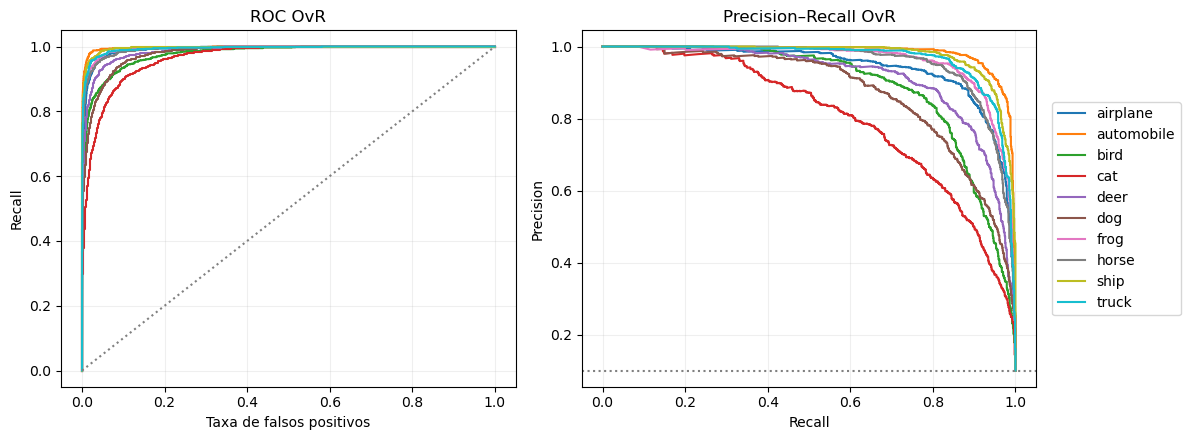

In [6]:
with np.load(reports / 'test_predictions.npz') as predictions:
    test_labels = predictions['labels']
    probabilities = predictions['probabilities']

fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(12, 4.5))
for class_id, name in enumerate(class_report.index):
    actual = test_labels == class_id
    scores = probabilities[:, class_id]
    fpr, tpr, _ = roc_curve(actual, scores)
    precision, recall, _ = precision_recall_curve(actual, scores)
    ax_roc.plot(fpr, tpr, label=name)
    ax_pr.plot(recall, precision, label=name)
ax_roc.plot([0, 1], [0, 1], ':', color='gray')
ax_pr.axhline(0.1, ls=':', color='gray')
ax_roc.set(title='ROC OvR', xlabel='Taxa de falsos positivos', ylabel='Recall')
ax_pr.set(title='Precision–Recall OvR', xlabel='Recall', ylabel='Precision')
for ax in (ax_roc, ax_pr):
    ax.grid(alpha=0.2)
ax_pr.legend(loc='center left', bbox_to_anchor=(1.02, 0.5))
fig.tight_layout()
plt.show()

## Leitura do resultado

- O modelo acertou **8.527 de 10.000 imagens**. A acurácia foi **85,27%**, 0,25 ponto percentual abaixo dos 85,52% observados na validação do mesmo checkpoint.
- **Gato** teve o menor F1 (71,24%). As duas maiores confusões foram cachorro → gato (131 imagens) e gato → cachorro (98).
- Os resultados descrevem a avaliação do checkpoint congelado. A seleção do modelo e a definição dos hiperparâmetros foram concluídas na validação.